In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from pathlib import Path
from lime.lime_tabular import LimeTabularExplainer
from sklearn.linear_model import LogisticRegression

# Project paths
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"
OUT = ROOT / "outputs" / "comparison"
OUT.mkdir(parents=True, exist_ok=True)

# Load data
X_train = pd.read_csv(DATA / "X_train.csv")
X_test = pd.read_csv(DATA / "X_test.csv")

y_test = pd.read_csv(
    DATA / "y_test.csv"
).squeeze("columns")

# Load trained model
model = joblib.load(
    ROOT / "models" / "best_model.joblib"
)

preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

if not isinstance(classifier, LogisticRegression):
    raise ValueError(
        "This comparison expects Logistic Regression."
    )

FEATURES = list(X_train.columns)

categorical = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

numeric = [
    col for col in FEATURES
    if col not in categorical
]

# Select first five test patients
patients = X_test.iloc[:5].copy()

print("Model loaded successfully!")
print("Patients selected:", len(patients))
print("Features:", len(FEATURES))

display(patients)

Model loaded successfully!
Patients selected: 5
Features: 13


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,61,0,0,145,307,0,0,146,1,1.0,1,0,3
1,59,1,3,170,288,0,0,159,0,0.2,1,0,3
2,67,1,0,120,229,0,0,129,1,2.6,1,2,3
3,67,1,2,152,212,0,0,150,0,0.8,1,0,3
4,61,0,0,130,330,0,0,169,0,0.0,2,0,2


In [2]:
# Transform data for SHAP
def transform_data(X):
    values = preprocessor.transform(X)

    if hasattr(values, "toarray"):
        values = values.toarray()

    return pd.DataFrame(
        values,
        columns=preprocessor.get_feature_names_out()
    )

train_encoded = transform_data(X_train)
patients_encoded = transform_data(patients)

# SHAP explainer
shap_explainer = shap.LinearExplainer(
    classifier,
    train_encoded
)

shap_values = shap_explainer(
    patients_encoded
).values

# LIME explainer
categorical_indices = [
    FEATURES.index(col)
    for col in categorical
]

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(dtype=float),
    feature_names=FEATURES,
    class_names=["Class 0", "Class 1"],
    categorical_features=categorical_indices,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Prediction function for LIME
def predict_fn(rows):
    df = pd.DataFrame(rows, columns=FEATURES)

    for col in categorical:
        df[col] = df[col].round().astype(int)

    return model.predict_proba(df)

print("SHAP and LIME initialized successfully!")

Background dataset has 241 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=241 when initializing the masker.


SHAP and LIME initialized successfully!


In [3]:
# Match transformed features to original features
encoded_names = list(
    preprocessor.get_feature_names_out()
)

feature_groups = {}

for col in FEATURES:
    if col in numeric:
        indices = [
            j for j, name in enumerate(encoded_names)
            if name == f"num__{col}"
        ]
    else:
        indices = [
            j for j, name in enumerate(encoded_names)
            if name.startswith(f"cat__{col}_")
        ]

    if not indices:
        raise ValueError(f"Feature mapping failed: {col}")

    feature_groups[col] = indices

all_results = []
patient_summary = []

for i in range(5):

    patient = patients.iloc[[i]]
    patient_array = patient.iloc[0].to_numpy(dtype=float)

    prediction = int(model.predict(patient)[0])
    probability = float(
        model.predict_proba(patient)[0, 1]
    )

    # Aggregate SHAP contributions
    shap_scores = {
        col: float(shap_values[i, indices].sum())
        for col, indices in feature_groups.items()
    }

    # Generate LIME explanation
    lime_exp = lime_explainer.explain_instance(
        data_row=patient_array,
        predict_fn=predict_fn,
        labels=(1,),
        num_features=len(FEATURES),
        num_samples=3000
    )

    lime_scores = {
        FEATURES[index]: float(weight)
        for index, weight in lime_exp.as_map()[1]
    }

    # Save contributions for every feature
    for col in FEATURES:
        all_results.append({
            "Patient": i + 1,
            "Feature": col,
            "SHAP_Value": shap_scores[col],
            "LIME_Weight": lime_scores.get(col, 0.0)
        })

    # Compare top five influential features
    shap_top = sorted(
        FEATURES,
        key=lambda x: abs(shap_scores[x]),
        reverse=True
    )[:5]

    lime_top = sorted(
        FEATURES,
        key=lambda x: abs(lime_scores.get(x, 0)),
        reverse=True
    )[:5]

    overlap = len(set(shap_top) & set(lime_top))

    patient_summary.append({
        "Patient": i + 1,
        "Actual": int(y_test.iloc[i]),
        "Prediction": prediction,
        "Class_1_Probability": probability,
        "Top_SHAP_Feature": shap_top[0],
        "Top_LIME_Feature": lime_top[0],
        "Top_5_Overlap": overlap
    })

    # Save LIME interactive explanation
    lime_exp.save_to_file(
        str(OUT / f"patient_{i+1}_lime.html")
    )

    print(f"Patient {i+1} completed!")

# Save results
comparison_df = pd.DataFrame(all_results)
summary_df = pd.DataFrame(patient_summary)

comparison_df.to_csv(
    OUT / "shap_lime_comparison.csv",
    index=False
)

summary_df.to_csv(
    OUT / "five_patient_summary.csv",
    index=False
)

print("\nComparison completed successfully!")
display(summary_df)

Patient 1 completed!
Patient 2 completed!
Patient 3 completed!
Patient 4 completed!
Patient 5 completed!

Comparison completed successfully!


,Patient,Actual,Prediction,Class_1_Probability,Top_SHAP_Feature,Top_LIME_Feature,Top_5_Overlap
0,1,0,0,0.215567,sex,ca,4
1,2,0,1,0.541224,ca,ca,3
2,3,0,0,0.003696,ca,ca,4
3,4,0,1,0.646427,ca,ca,4
4,5,0,1,0.951212,sex,ca,5


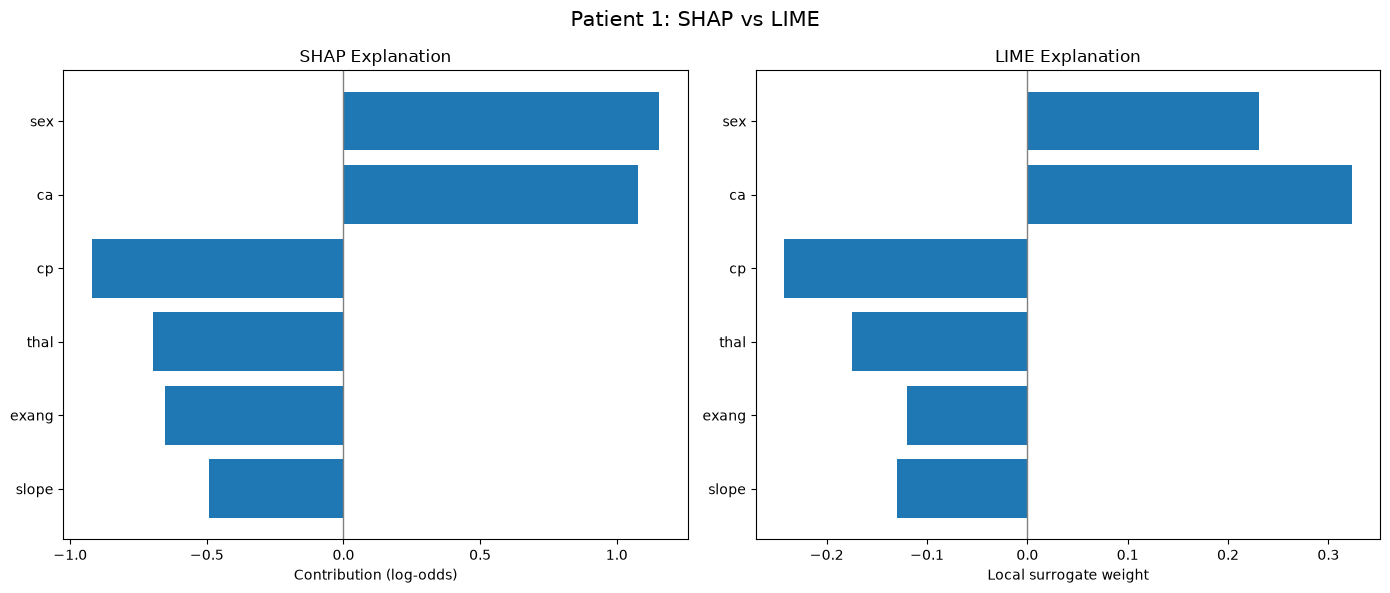

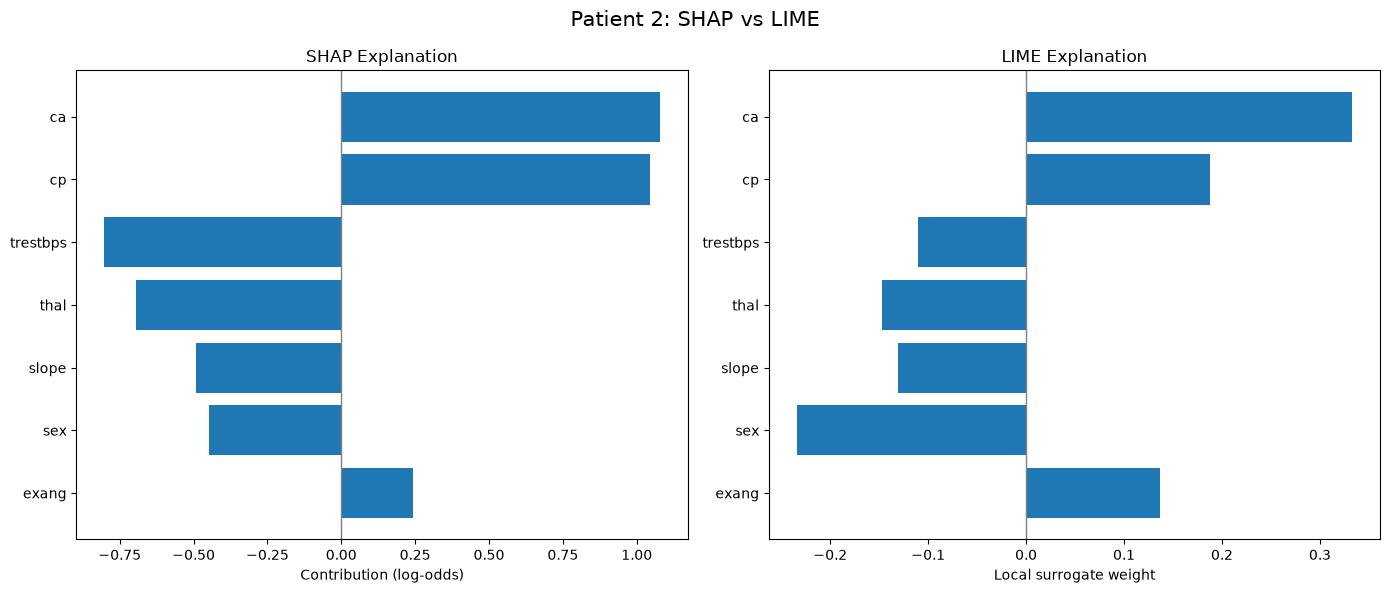

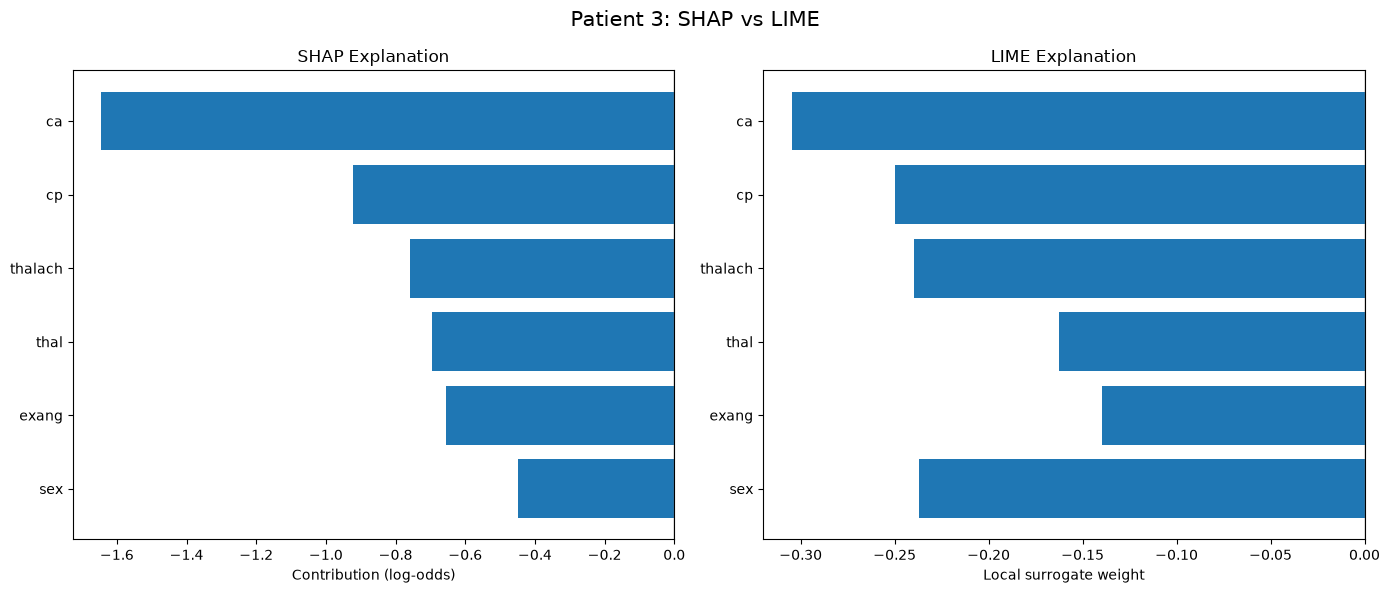

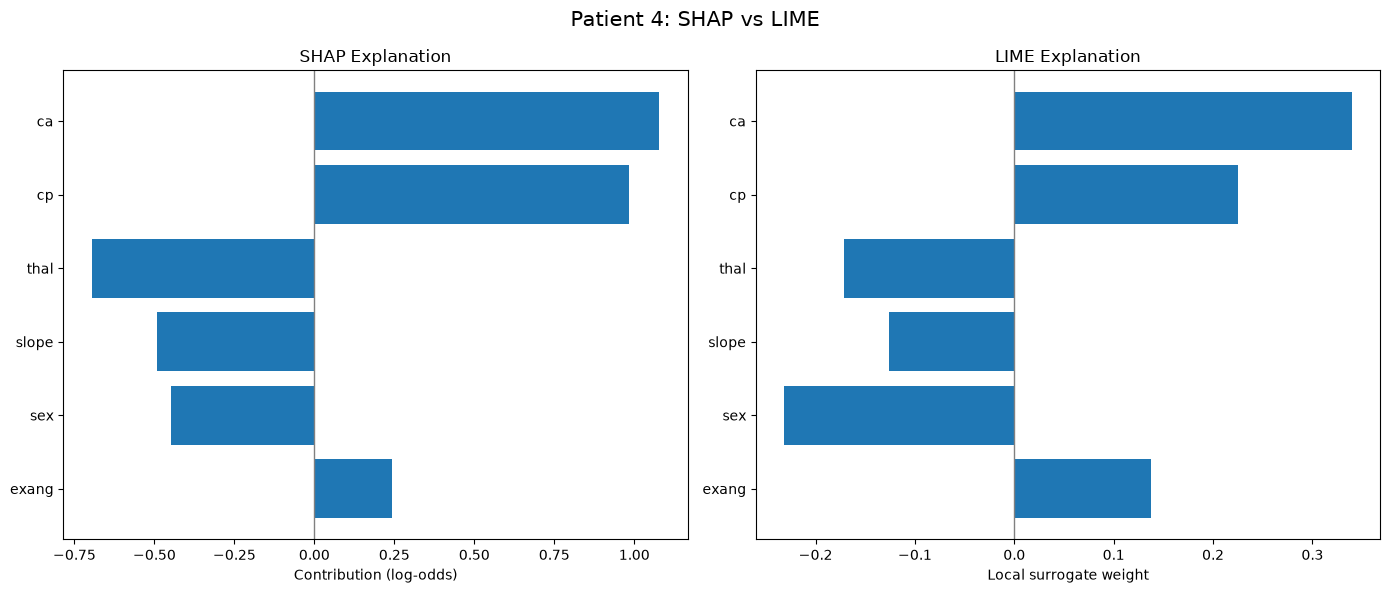

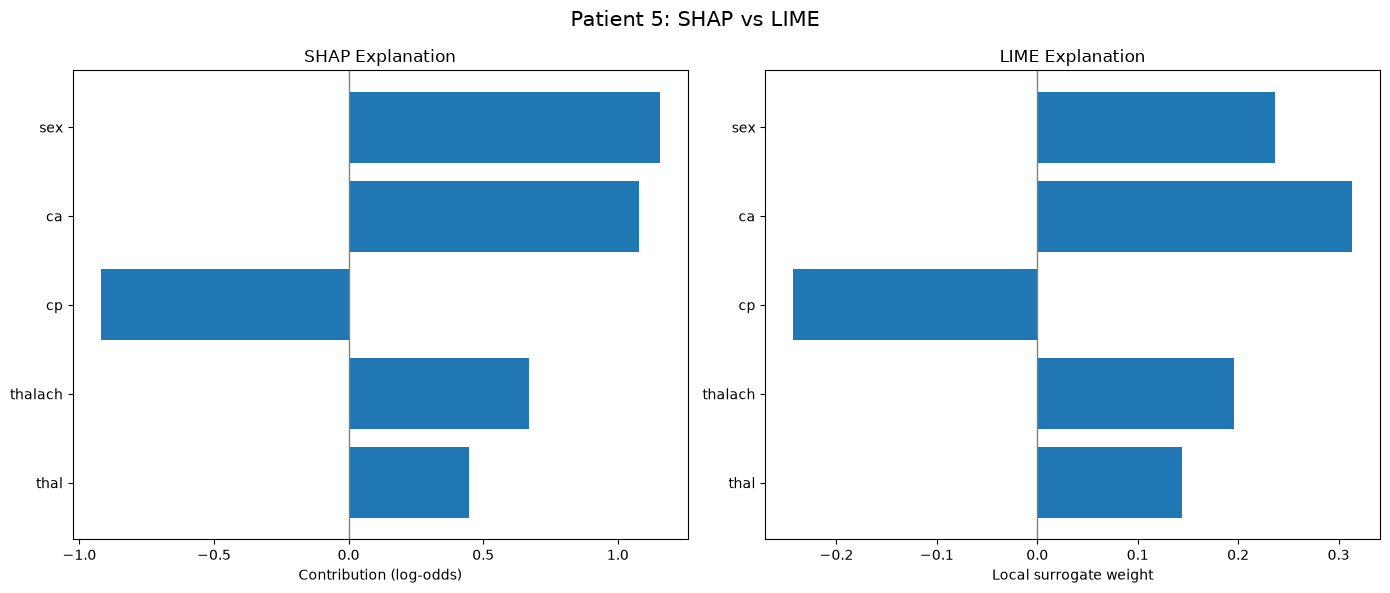

All five comparison graphs saved!


In [4]:
for patient_id in range(1, 6):

    df = comparison_df[
        comparison_df["Patient"] == patient_id
    ].set_index("Feature")

    # Include top five features from each method
    shap_top = df["SHAP_Value"].abs().nlargest(5).index
    lime_top = df["LIME_Weight"].abs().nlargest(5).index

    selected_features = list(
        dict.fromkeys(list(shap_top) + list(lime_top))
    )

    shap_data = df.loc[selected_features, "SHAP_Value"]
    lime_data = df.loc[selected_features, "LIME_Weight"]

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # SHAP chart
    axes[0].barh(
        selected_features,
        shap_data
    )
    axes[0].axvline(0, color="gray", linewidth=1)
    axes[0].invert_yaxis()
    axes[0].set_title("SHAP Explanation")
    axes[0].set_xlabel("Contribution (log-odds)")

    # LIME chart
    axes[1].barh(
        selected_features,
        lime_data
    )
    axes[1].axvline(0, color="gray", linewidth=1)
    axes[1].invert_yaxis()
    axes[1].set_title("LIME Explanation")
    axes[1].set_xlabel("Local surrogate weight")

    fig.suptitle(
        f"Patient {patient_id}: SHAP vs LIME",
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        OUT / f"patient_{patient_id}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All five comparison graphs saved!")

In [5]:
print("SHAP vs LIME - Five Patient Analysis")
print("-" * 45)

for _, row in summary_df.iterrows():

    print(f"\nPatient {int(row['Patient'])}")

    print("Actual Class:", int(row["Actual"]))
    print("Predicted Class:", int(row["Prediction"]))

    print(
        "Class 1 Probability:",
        f"{row['Class_1_Probability']:.2%}"
    )

    print(
        "Top SHAP Feature:",
        row["Top_SHAP_Feature"]
    )

    print(
        "Top LIME Feature:",
        row["Top_LIME_Feature"]
    )

    print(
        "Shared Top-5 Features:",
        int(row["Top_5_Overlap"]),
        "out of 5"
    )

print("\nAverage top-5 feature overlap:",
      round(summary_df["Top_5_Overlap"].mean(), 2))

print("\nAll comparison results saved successfully!")

SHAP vs LIME - Five Patient Analysis
---------------------------------------------

Patient 1
Actual Class: 0
Predicted Class: 0
Class 1 Probability: 21.56%
Top SHAP Feature: sex
Top LIME Feature: ca
Shared Top-5 Features: 4 out of 5

Patient 2
Actual Class: 0
Predicted Class: 1
Class 1 Probability: 54.12%
Top SHAP Feature: ca
Top LIME Feature: ca
Shared Top-5 Features: 3 out of 5

Patient 3
Actual Class: 0
Predicted Class: 0
Class 1 Probability: 0.37%
Top SHAP Feature: ca
Top LIME Feature: ca
Shared Top-5 Features: 4 out of 5

Patient 4
Actual Class: 0
Predicted Class: 1
Class 1 Probability: 64.64%
Top SHAP Feature: ca
Top LIME Feature: ca
Shared Top-5 Features: 4 out of 5

Patient 5
Actual Class: 0
Predicted Class: 1
Class 1 Probability: 95.12%
Top SHAP Feature: sex
Top LIME Feature: ca
Shared Top-5 Features: 5 out of 5

Average top-5 feature overlap: 4.0

All comparison results saved successfully!
